In [1]:
# Project: Smart Factory — Predict Machine Failures
# Imagine a factory has machines running all day. If one breaks unexpectedly, production stops and repairs cost money.
# Can we use machine sensor data to predict failures before they happen?
# We'll investigate that using Machine Learning.


# Precision: Of the machines predicted to fail, how many actually fail?
# Recall: Of all machines that actually fail, how many did our model detect?
# F1-score: One score that balances precision and recall.

In [2]:
# LOAD THE DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("ai4i2020.csv")
print("Data loaded sucessfully")
print("Shape:", df.shape)
df.head()

Data loaded sucessfully
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [5]:
# CHECK FOR DUPLICATED VALUES
df.duplicated().sum()

np.int64(0)

In [6]:
# CHECK THE TARGET COLUMN DISTRIBUTION ( LEST SEE HOW MANY MACHINES FAILED AND DIDN'T)
df["Machine failure"].value_counts()


# Good! Our dataset has class imbalance.
# - No failure (0): 9,661 machines
# - Failure (1): 339 machines
# - Only 3.39% of records show machine failure.
# This matters because a model could predict “no failure” for every machine and still achieve 96.61% accuracy, while failing to detect actual failures.

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [7]:
# CHECK THE BASIC STATISTICS
df.describe()


# - Mean air temperature: 300.00 K
# - Mean rotational speed: 1538.78 rpm
# - Mean torque: 39.99 Nm
# - Mean tool wear: 107.95 minutes
# Notice that the failure-related columns are mostly 0, which matches our earlier finding that failures are uncommon.

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


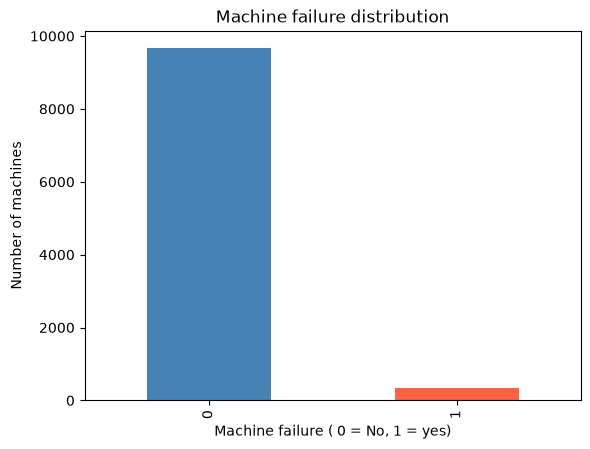

In [8]:
# LETS VISUALIZE MACHINE FAILURES
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().sort_index().plot(
    kind = "bar",
    color = ["steelblue","tomato"]
)
plt.title("Machine failure distribution")
plt.xlabel("Machine failure ( 0 = No, 1 = yes)")
plt.ylabel("Number of machines")
plt.show()

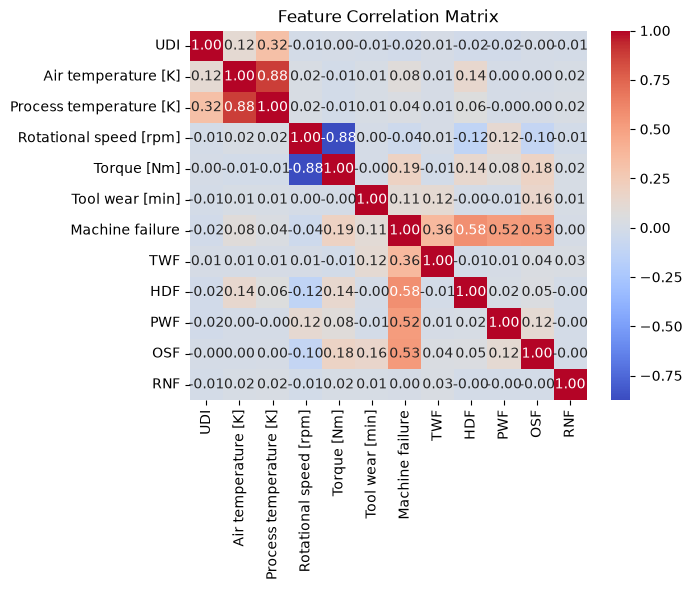

In [9]:
# EXPLORE THE RELATIONSHIPS B/W NUMERICAL FEATURES
import seaborn as sns

numeric_df = df.select_dtypes(include = "number")

sns.heatmap(
    numeric_df.corr(),
    annot = True,
    cmap = "coolwarm",
    fmt =".2f"
)
plt.title("Feature Correlation Matrix")
plt.show()


# Air temperature vs Process temperature: 0.88 — strong positive correlation; they tend to increase together.
# Rotational speed vs Torque: -0.88 — strong negative correlation; higher rotational speed tends to be associated with lower torque.
# Machine failure vs HDF: 0.58 — a positive relationship in this dataset. However, we must not use HDF as a feature because it is a failure-mode label that can leak information about the target.

In [10]:
# SEPERATE THE FEATURES AND TARGET
# Features (X) — information used to make predictions.
# Target (y) — the result we want to predict.
X = df.drop(
    columns = [
        "UDI", "Product ID", "Machine failure",
        "TWF", "HDF", "PWF", "OSF", "RNF"
    ]
)
y = df["Machine failure"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", X.columns.tolist())

Features shape: (10000, 6)
Target shape: (10000,)
Feature columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [11]:
# SPLIT THE DATA INTO TRAINING AND TESTING SETS
# Training data: used to teach the model.
# Testing data: used to evaluate how well it predicts unseen data.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)
print("Testing features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Testing features: (8000, 6)
Testing features: (2000, 6)
Training target: (8000,)
Testing target: (2000,)


In [12]:
X_train_encoded = pd.get_dummies(X_train, columns=["Type"], dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=["Type"], dtype=int)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)
print(X_train_encoded.head())


# Our dataset now has 8 numerical features: five sensor measurements and three columns representing machine type (Type_H, Type_L, Type_M).

Training shape: (8000, 8)
Testing shape: (2000, 8)
      Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
4058                302.0                    310.9                    1456   
1221                297.0                    308.3                    1399   
6895                301.0                    311.6                    1357   
9863                298.9                    309.8                    1411   
8711                297.1                    308.5                    1733   

      Torque [Nm]  Tool wear [min]  Type_H  Type_L  Type_M  
4058         47.2               54       0       0       1  
1221         46.4              132       0       0       1  
6895         45.6              137       0       0       1  
9863         56.3               84       0       1       0  
8711         28.7               50       0       1       0  


In [13]:
# TRAIN OUR FIRST ML MODEL
# LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter = 1000)
model.fit(X_train_encoded, y_train)
print("Model training completed!")

Model training completed!


In [14]:
# MAKE PREDICTIONS 
y_pred = model.predict(X_test_encoded)

print("First 30 actual values:")
print(y_test.head(30).tolist())

print("\n First 30 predicted values:")
print(y_pred[:30])

First 30 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]

 First 30 predicted values:
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [15]:
# EVALUATE MODEL ACCURACY
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuarcy:", accuracy)
print("Accuracy:", accuracy * 100, "%")

Accuarcy: 0.9685
Accuracy: 96.85000000000001 %


In [16]:
# CLASSIFICATION REPORT 
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

# Precision = 67%: When the model predicts a failure, it is correct about 67% of the time.
# Recall = 15%: It detects only around 15% of actual failures, missing approximately 85%.
# F1-score = 0.24: Its overall balance between precision and recall for failures is poor.

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.67      0.15      0.24        68

    accuracy                           0.97      2000
   macro avg       0.82      0.57      0.61      2000
weighted avg       0.96      0.97      0.96      2000



[[1927    5]
 [  58   10]]


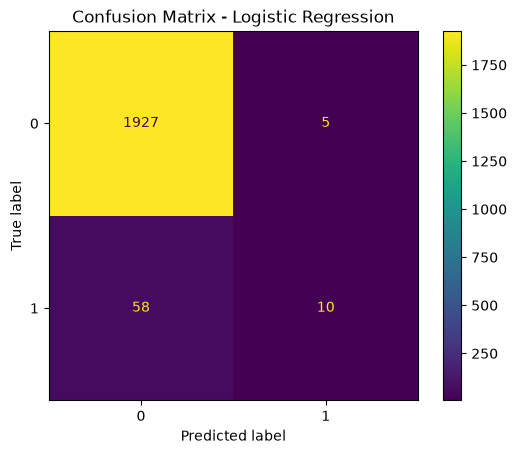

In [17]:
# UNDERSTAND THE MISTAKES WITH CONFUSION MATRIX
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# Actual vs predicted	Count	Meaning
# True Negative	1,927	Correctly predicted no failure
# False Positive	5	False alarms
# False Negative	58	Missed actual failures
# True Positive	10	Correctly detected failures
# Our main problem: The model missed 58 out of 68 actual failures. It detected only 10.

In [18]:
# IMPROVE THE MODEL USING CLASS WERIGHTS
model_balanced = LogisticRegression(
    max_iter = 1000,
    class_weight = "balanced"
)
model_balanced.fit(X_train_encoded, y_train)
y_pred_balanced = model_balanced.predict(X_test_encoded)
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.83      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.83      0.88      2000



[[1598  334]
 [  12   56]]


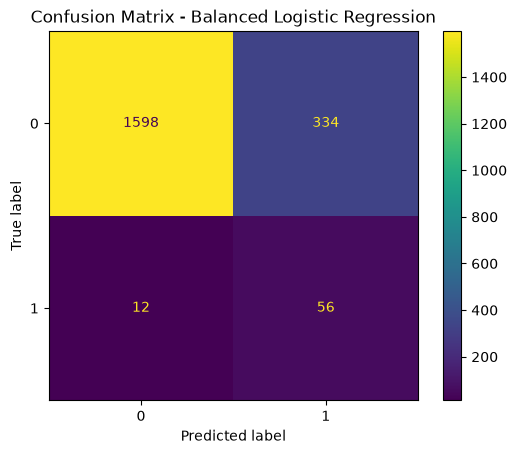

In [19]:
# COMPARE THE ERROS IN THE CONFUSION MATRIX
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_balanced
)
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()


# Result	Original model	Balanced model
# Correctly detected failures	10	56
# Missed failures	58	12
# False alarms	5	334
# Accuracy	96.85%	82.7%
# Key lesson: class_weight="balanced" helps the model detect more failures, but it creates many more false alarms. The best model depends on the cost of missed failures versus unnecessary inspections.

In [20]:
# MOVE TO DECISION TREE ALGORITHM
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    class_weight = "balanced",
    max_depth = 5,
    random_state = 42
)
tree_model.fit(X_train_encoded, y_train)
y_pred_tree = tree_model.predict(X_test_encoded)
print(classification_report(y_test, y_pred_tree))


# Metric for failure (class 1)	Logistic Regression (balanced)	Decision Tree
# Precision	                                      14%	            31%
# Recall	                                      82%	            88%
# F1-score	                                      0.24	            0.46
# Accuracy	                                      83%	            93%

              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1932
           1       0.31      0.88      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.91      0.71      2000
weighted avg       0.97      0.93      0.95      2000



In [21]:
# RANDOM FOREST 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf_model = RandomForestClassifier(
    n_estimators = 100, # builds 100 trees
    class_weight = "balanced", 
    random_state = 42,
    n_jobs = -1 #uses all available CPU cores for training.
)

rf_model.fit(X_train_encoded, y_train)

y_pred_rf = rf_model.predict(X_test_encoded)

print(classification_report(y_test, y_pred_rf))



# Metric for failure (class 1)	Logistic Regression (balanced)	Decision Tree	Random Forest
# Precision	                                   14%	                   31%	          70%
# Recall	                                   82%	                   88%	          65%
# F1-score	                                   0.24	                   0.46	          0.67
# Accuracy	                                   83%	                   93%	          98%

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.65      0.67        68

    accuracy                           0.98      2000
   macro avg       0.84      0.82      0.83      2000
weighted avg       0.98      0.98      0.98      2000



In [22]:
# K-NEAREST NEIGHBORS (KNN)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (8000, 8)
Testing shape: (2000, 8)


In [23]:
# TRAIN AND EVALUVATE KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

knn_model = KNeighborsClassifier(n_neighbors = 5) #n_neighbors=5 means the model considers the five nearest neighbors.

knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_knn))


              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.83      0.29      0.43        68

    accuracy                           0.97      2000
   macro avg       0.90      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



In [24]:
# Model	Failure Precision	Failure Recall	Failure F1-score	Accuracy
# Logistic Regression (balanced)	14%	82%	0.24	83%
# Decision Tree	31%	88%	0.46	93%
# Random Forest	70%	65%	0.67	98%
# KNN	83%	29%	0.43	97%

In [25]:
# SUPPORT VECTOR MACHINE
# TRAIN THE SVM
from sklearn.svm import SVC
from sklearn.metrics import classification_report
svm_model = SVC(
    class_weight = "balanced",
    random_state = 42
)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       1.00      0.92      0.96      1932
           1       0.28      0.91      0.43        68

    accuracy                           0.92      2000
   macro avg       0.64      0.91      0.69      2000
weighted avg       0.97      0.92      0.94      2000



In [26]:
# Suppose there are 10 actual machine failures. Our model predicts 5 machines will fail, and 4 of those predictions are correct.
# Metric	Result	Meaning
# Precision	4/5 = 80%	4 of 5 failure warnings were correct
# Recall	4/10 = 40%	Detected 4 of 10 actual failures
# F1-score	53%	Balances precision and recall

In [27]:
# Model	Failure Precision	Failure Recall	Failure F1-score
# Logistic Regression (balanced)	14%	82%	0.24
# Decision Tree	31%	88%	0.46
# Random Forest	70%	65%	0.67
# KNN	83%	29%	0.43
# SVM (balanced)	28%	91%	0.43

In [28]:
# GRADIENT BOOSTING
# TRAIN GB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

sample_weights = compute_sample_weight(
    class_weight = "balanced",
    y = y_train
)


gb_model = GradientBoostingClassifier(random_state = 42)

gb_model.fit(
    X_train_encoded,
    y_train,
    sample_weight = sample_weights
)

y_pred_gb = gb_model.predict(X_test_encoded)

print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       1.00      0.94      0.96      1932
           1       0.32      0.87      0.47        68

    accuracy                           0.93      2000
   macro avg       0.66      0.90      0.72      2000
weighted avg       0.97      0.93      0.95      2000



In [29]:
# Compare our six models
# Model	Precision (Failure)	Recall (Failure)	F1-score
# Logistic Regression (balanced)	14%	82%	0.24
# Decision Tree	31%	88%	0.46
# Random Forest	70%	65%	0.67
# KNN	83%	29%	0.43
# SVM (balanced)	28%	91%	0.43
# Gradient Boosting (weighted)	32%	87%	0.47

In [30]:
# XGBOOST
# XGBoost is an advanced boosting algorithm that builds decision trees sequentially, correcting earlier errors while improving predictions.
%pip show xgboost

Name: xgboost
Version: 3.4.1
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: C:\Users\acer\anaconda3\Lib\site-packages
Requires: numpy, scipy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [32]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Rename columns to remove unsupported characters
X_train_xgb = X_train_encoded.copy()
X_test_xgb = X_test_encoded.copy()

X_train_xgb.columns = [
    col.replace("[", "").replace("]", "").replace("<", "")
    for col in X_train_xgb.columns
]

X_test_xgb.columns = X_train_xgb.columns

# Create and train XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_xgb, y_train)

y_pred_xgb = xgb_model.predict(X_test_xgb)

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.90      0.69      0.78        68

    accuracy                           0.99      2000
   macro avg       0.95      0.84      0.89      2000
weighted avg       0.99      0.99      0.99      2000



In [33]:
# Model	                         Failure Precision	Failure Recall	Failure F1-score
# Logistic Regression (balanced)	14%	82%	0.24
# Decision Tree	31%	88%	0.46
# Random Forest	70%	65%	0.67
# KNN	83%	29%	0.43
# SVM (balanced)	28%	91%	0.43
# Gradient Boosting	32%	87%	0.47
# XGBoost	90%	69%	0.78

In [34]:
# XGBOOST HYPERPARAMETER TUNING
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_tuning = GridSearchCV(
    estimator=XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ),
    param_grid=param_grid,
    scoring=make_scorer(f1_score),
    cv=cv,
    n_jobs=-1,
    verbose=1
)

xgb_tuning.fit(X_train_xgb, y_train)

print("Best parameters:", xgb_tuning.best_params_)
print("Best cross-validation F1-score:", xgb_tuning.best_score_)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best cross-validation F1-score: 0.7139298065329933


In [35]:
# EVALUATE THE TUNED XGBOOST MODEL
from sklearn.metrics import classification_report
best_xgb_model = xgb_tuning.best_estimator_
y_pred_tuned_xgb = best_xgb_model.predict(X_test_xgb)
print(classification_report(y_test, y_pred_tuned_xgb))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.89      0.69      0.78        68

    accuracy                           0.99      2000
   macro avg       0.94      0.84      0.88      2000
weighted avg       0.99      0.99      0.99      2000



In [36]:
# Failure metric	Original XGBoost	Tuned XGBoost
# Precision	                     90%	89%
# Recall	                     69%	69%
# F1-score	                     0.78	0.78
# Accuracy	                     99%	99%

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_tuning = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring=make_scorer(f1_score),
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_tuning.fit(X_train_encoded, y_train)

print("Best parameters:", rf_tuning.best_params_)
print("Best cross-validation F1-score:", rf_tuning.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best cross-validation F1-score: 0.6654353204172876


In [40]:
# EVALUATE TUNED RANDOM FOREST
from sklearn.metrics import classification_report

best_rf_model = rf_tuning.best_estimator_

y_pred_tuned_rf = best_rf_model.predict(X_test_encoded)

print(classification_report(y_test, y_pred_tuned_rf))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.59      0.78      0.67        68

    accuracy                           0.97      2000
   macro avg       0.79      0.88      0.83      2000
weighted avg       0.98      0.97      0.98      2000



In [41]:
# Failure metric	TunedRandomForest	Tuned XGBoost
# Precision	                       59%	89%
# Recall	                       78%	69%
# F1-score	                       0.67	0.78
# Accuracy	                       97%	99%

In [42]:
# FINE TUEN DECISION TREE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

dt_param_grid = {
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ["gini", "entropy"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dt_tuning = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    param_grid=dt_param_grid,
    scoring=make_scorer(f1_score),
    cv=cv,
    n_jobs=-1,
    verbose=1
)

dt_tuning.fit(X_train_encoded, y_train)

print("Best parameters:", dt_tuning.best_params_)
print("Best cross-validation F1-score:", dt_tuning.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1}
Best cross-validation F1-score: 0.6541667206761118


In [43]:
# EVALUATE TUNED DECISION TREE
from sklearn.metrics import classification_report

best_dt_model = dt_tuning.best_estimator_

y_pred_tuned_dt = best_dt_model.predict(X_test_encoded)

print(classification_report(y_test, y_pred_tuned_dt))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.69      0.70        68

    accuracy                           0.98      2000
   macro avg       0.85      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [44]:
# Model	          Precision	Recall	F1-score
# Decision Tree	        71%	69%	0.70
# Random Forest	        59%	78%	0.67
# XGBoost	                89%	69%	0.78

In [45]:
# BEFORE SELECTING THE MODEL WE WILL COMPARE ALL THE MODEL AT ONCE
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

models = {
    "Logistic Regression (balanced)": y_pred_balanced,
    "Decision Tree (original)": y_pred_tree,
    "Random Forest (original)": y_pred_rf,
    "KNN": y_pred_knn,
    "SVM (balanced)": y_pred_svm,
    "Gradient Boosting": y_pred_gb,
    "XGBoost (original)": y_pred_xgb,
    "Decision Tree (tuned)": y_pred_tuned_dt,
    "Random Forest (tuned)": y_pred_tuned_rf,
    "XGBoost (tuned)": y_pred_tuned_xgb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score", ascending=False
)

results_df.round(3)

,Model,Precision,Recall,F1-score,Accuracy
6,XGBoost (original),0.904,0.691,0.783,0.987
9,XGBoost (tuned),0.887,0.691,0.777,0.986
7,Decision Tree (tuned),0.712,0.691,0.701,0.980
2,Random Forest (original),0.698,0.647,0.672,0.978
8,Random Forest (tuned),0.589,0.779,0.671,0.974
5,Gradient Boosting,0.324,0.868,0.472,0.934
1,Decision Tree (original),0.311,0.882,0.460,0.930
3,KNN,0.833,0.294,0.435,0.974
4,SVM (balanced),0.279,0.912,0.428,0.917
0,Logistic Regression (balanced),0.144,0.824,0.245,0.827


In [46]:
# Our next steps are:
# 1. Tune the classification threshold to explore the trade-off between precision and recall.
# 2. Select the preferred model and threshold using training data and cross-validation.
# 3. Evaluate the final choice on a fresh, untouched test set if possible.
# 4. Save the model for future predictions.

In [50]:
# THRESHOLD TUNING FOR XGBOOST (ORIGINAL)
from sklearn.model_selection import cross_val_predict, StratifiedKFold
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

off_probabilities = cross_val_predict(
    xgb_model,
    X_train_xgb,
    y_train,
    cv = cv,
    method = "predict_proba",
    n_jobs = -1
)[:,1]
print("1st 10 probabilities:")
print(off_probabilities[:10])

1st 10 probabilities:
[0.0037247  0.00158433 0.00120991 0.00762063 0.00066395 0.00061842
 0.0008957  0.00061989 0.00099973 0.00057726]


In [51]:
# NOW COMPARE WITH DIFFERENT THRESHOLD
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (off_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_train, y_pred_threshold, zero_division=0),
        "F1-score": f1_score(y_train, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score
0,0.1,0.514,0.841,0.638
1,0.2,0.665,0.804,0.728
2,0.3,0.727,0.745,0.736
3,0.4,0.782,0.701,0.739
4,0.5,0.803,0.631,0.707


In [53]:
# 1. Understand your results
# Threshold	Precision	Recall	F1-score
# 0.10	0.514	0.841	0.638
# 0.20	0.665	0.804	0.728
# 0.30	0.727	0.745	0.736
# 0.40	0.782	0.701	0.739
# 0.50	0.803	0.631	0.707

# Threshold 0.40 currently gives the best F1-score: 0.739.
# - At 0.10, the model catches more failures but creates more false alarms.
# - At 0.40, precision and recall are more balanced.
# - At 0.50, precision increases, but the model misses more actual failures.

In [55]:
# LETS TEST MORE THRESHOLDS AROUND 0.40 TO IMPOROVE THE F1 SCORE
thresholds = [0.32, 0.34, 0.36, 0.38, 0.40, 0.42, 0.44, 0.46, 0.48]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (off_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_train, y_pred_threshold, zero_division=0),
        "F1-score": f1_score(y_train, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.sort_values("F1-score", ascending=False).round(3)

,Threshold,Precision,Recall,F1-score
0,0.32,0.744,0.742,0.743
3,0.38,0.777,0.708,0.741
1,0.34,0.750,0.731,0.740
4,0.40,0.782,0.701,0.739
2,0.36,0.764,0.716,0.739
5,0.42,0.784,0.697,0.738
6,0.44,0.783,0.679,0.727
7,0.46,0.784,0.668,0.721
8,0.48,0.793,0.649,0.714


In [56]:
# . Best threshold: 0.32
# Your highest F1-score is 0.743 at threshold 0.32.
# - Precision: 74.4% — about 74 out of every 100 predicted failures are actual failures.
# - Recall: 74.2% — the model catches about 74 out of every 100 actual failures.
# - F1-score: 0.743 — a balanced measure of precision and recall.
# For our predictive maintenance project, 0.32 is currently the best threshold among those tested. We should still validate it before treating it as the final choice.

In [57]:
# EVALUATE THE (0.32) THRESHOLD
from sklearn.metrics import classification_report, confusion_matrix

y_test_probabilities = xgb_model.predict_proba(X_test_xgb)[:, 1]

y_test_threshold = (y_test_probabilities >= 0.32).astype(int)

print("Classification Report:")
print(classification_report(y_test, y_test_threshold))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_threshold))

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.80      0.76      0.78        68

    accuracy                           0.99      2000
   macro avg       0.90      0.88      0.89      2000
weighted avg       0.99      0.99      0.99      2000

Confusion Matrix:
[[1919   13]
 [  16   52]]


In [58]:
# Excellent! 🎯 Our XGBoost model is detecting machine failures with a good balance between precision and recall at threshold 0.32.
# 1. Understand the final results
# Accuracy
# 98.55%

# Failure F1-score
# 0.78

# Failure recall
# 76.5%

# Failure precision
# 80%

In [59]:
# - 1,919: Correctly predicted no failure.
# - 13: False alarms.
# - 16: Actual failures missed by the model.
# - 52: Actual failures correctly detected.
# The model detected 52 of the 68 actual failures in the test set.

In [61]:
# SAVE OUR TRAINED MODEL
import joblib 
model_artifact = {
    "model":xgb_model,
    "feature_columns":list(X_train_xgb.columns),
    "threshold":0.32
}
joblib.dump(model_artifact, "machine_failure_model.pkl")
print("model saved successfully")

model saved successfully


In [62]:
# LOAD AND TEST THE MODEL
import joblib

# Load the saved model
loaded_artifact = joblib.load("machine_failure_model.pkl")

loaded_model = loaded_artifact["model"]
feature_columns = loaded_artifact["feature_columns"]
threshold = loaded_artifact["threshold"]

print("Model loaded successfully!")
print("Threshold:", threshold)
print("Number of features:", len(feature_columns))

Model loaded successfully!
Threshold: 0.32
Number of features: 8


In [63]:
# LETS MAKE A PREDICTION ON A NEW MACHINE
import pandas as pd

# Create one sample machine
new_machine = pd.DataFrame([{
    "Type_H": 0,
    "Type_L": 1,
    "Type_M": 0,
    "Air temperature  K": 300.0,
    "Process temperature  K": 310.0,
    "Rotational speed  rpm": 1500,
    "Torque  Nm": 40.0,
    "Tool wear  min": 100
}])

# Ensure the features are in the correct order
new_machine = new_machine[feature_columns]

# Predict failure probability
failure_probability = loaded_model.predict_proba(new_machine)[0][1]

# Apply our selected threshold
prediction = int(failure_probability >= threshold)

print(f"Failure probability: {failure_probability:.2%}")

if prediction == 1:
    print("Prediction: Machine failure detected")
else:
    print("Prediction: Machine failure not detected")

KeyError: "['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min'] not in index"

In [64]:
print(feature_columns)

['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Type_H', 'Type_L', 'Type_M']


In [65]:
import pandas as pd

new_machine = pd.DataFrame([{
    "Air temperature K": 300.0,
    "Process temperature K": 310.0,
    "Rotational speed rpm": 1500,
    "Torque Nm": 40.0,
    "Tool wear min": 100,
    "Type_H": 0,
    "Type_L": 1,
    "Type_M": 0
}])

# Arrange columns in the exact order expected by the model
new_machine = new_machine[feature_columns]

# Predict failure probability
failure_probability = loaded_model.predict_proba(new_machine)[0][1]

# Apply the selected threshold
prediction = int(failure_probability >= threshold)

print(f"Failure probability: {failure_probability:.2%}")

if prediction == 1:
    print("Prediction: Machine failure detected")
else:
    print("Prediction: Machine failure not detected")

Failure probability: 0.07%
Prediction: Machine failure not detected


In [66]:
# 0.07% probability: The model estimates a very low likelihood of failure for these sample readings.
# 32% threshold: The model predicts a failure only when its estimated probability reaches or exceeds 32%.
# Since 0.07% is below 32%, the model predicts no failure.

                 Feature  Importance
3              Torque Nm      0.2643
2   Rotational speed rpm      0.1679
4          Tool wear min      0.1661
0      Air temperature K      0.1365
1  Process temperature K      0.0878
7                 Type_M      0.0857
6                 Type_L      0.0513
5                 Type_H      0.0405


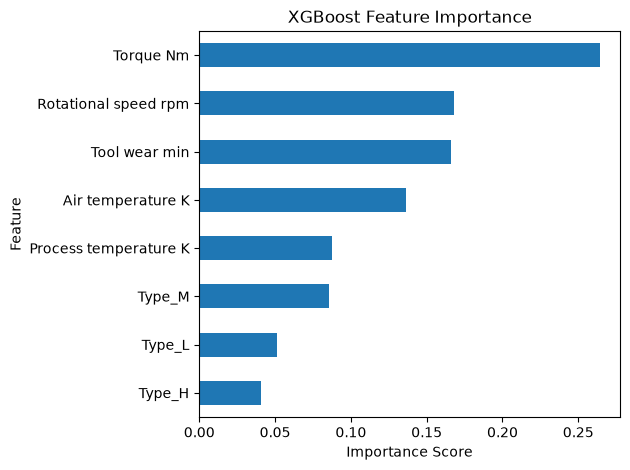

In [67]:
# FEATURE IMPORTANCE IN XGBOOST
# In our machine failure project, we want to know whether temperature, rotational speed, torque, tool wear, or machine type is most useful to the model.
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": loaded_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.round(4))

importance.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [68]:
# What does this tell us?
# - Torque is the most important feature for your trained model.
# - Rotational speed and tool wear are the next most important.
# - Machine type has comparatively lower importance in this model.
# - These scores describe how the model uses features; they do not prove causation or show whether a higher sensor reading increases failure risk.

In [69]:
# UNDERSTAND WHY THE MODEL PREDICTS FAILURE
# SHAP is a tool that helps explain individual machine-learning predictions. For our project, it can help us understand which sensor readings pushed a machine's predicted failure probability higher or lower.
%pip show shap

Note: you may need to restart the kernel to use updated packages.


In [70]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.2 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------

In [71]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


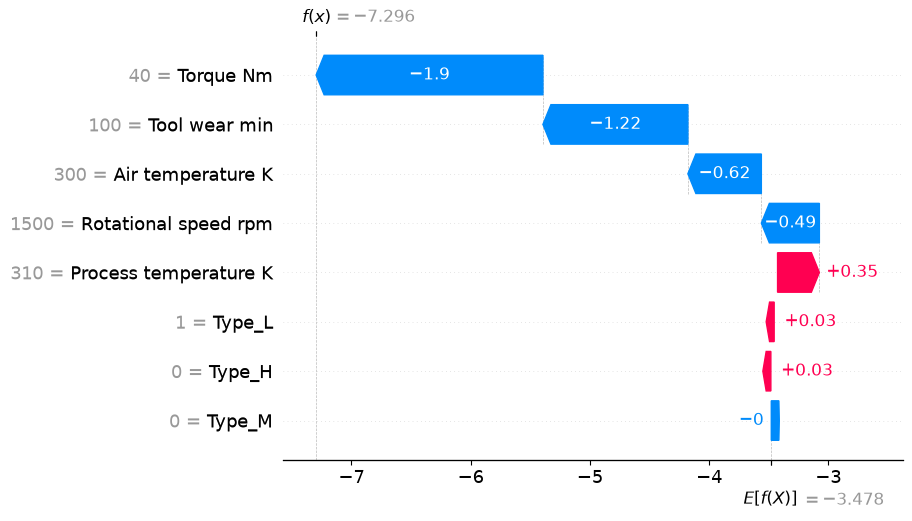

In [72]:
import shap

# Create an explainer for our trained XGBoost model
explainer = shap.TreeExplainer(loaded_model)

# Explain the prediction for our sample machine
shap_values = explainer(new_machine)

# Display the explanation
shap.plots.waterfall(shap_values[0])

In [73]:
# Your model's prediction is shown in log-odds, not directly in probability.
# - \(E[f(X)] = -3.478\): the model's baseline output.
# - \(f(x) = -7.296\): the model's output for your sample machine.
# - Blue bars: features pushing the prediction toward a lower failure risk.
# - Red bars: features pushing the prediction toward a higher failure risk.

In [75]:
# Torque = 40 Nm
# Contribution: −1.90
# This is the largest downward contribution in your chart.



# Tool wear = 100 min
# Contribution: −1.22
# This also pushes the prediction toward a lower failure risk.



# Air temperature = 300 K
# Contribution: −0.62
# This lowers the model's predicted failure score.



# Process temperature = 310 K
# Contribution: +0.35
# This pushes the prediction toward a higher failure risk.


# Your feature-importance chart showed that torque was the most important feature overall. The SHAP chart adds another level of detail: for this specific machine, torque pushes the prediction downward.
# That distinction matters:
# - Feature importance: Which features matter across the model overall?
# - SHAP: How do features contribute to one particular prediction?

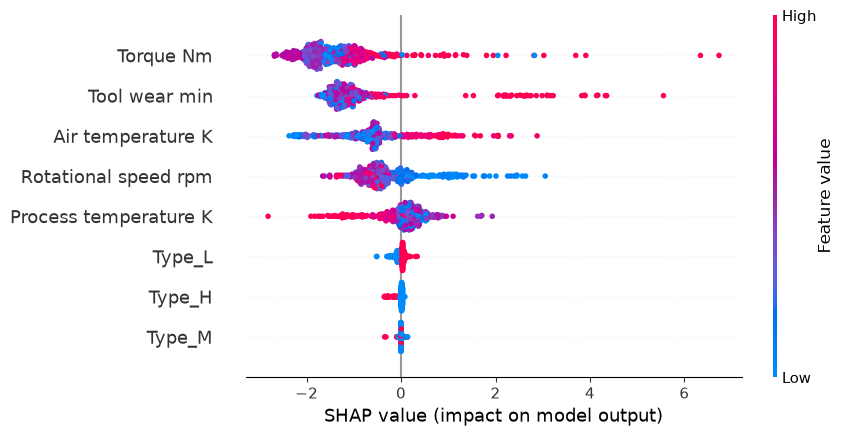

In [76]:
# VISUALIZE SHAP FOR ALL FEATURES
# Explain a sample of training rows
X_sample = X_train_xgb.sample(n=500, random_state=42)

shap_values_sample = explainer(X_sample)

# Show global feature impact
shap.plots.beeswarm(shap_values_sample)

In [77]:
# 1. How to read this chart
# - Each dot represents one machine sample.
# - Horizontal position: SHAP value. Positive values push the model toward predicting failure; negative values push it away from failure.
# - Pink dots: Higher feature values.
# - Blue dots: Lower feature values.
# - Features at the top generally have greater overall impact on the model's output.

# 2. What your chart tells us
# 1. Torque
# It has the greatest overall impact in this plot. Some high torque readings (pink dots) push the model toward failure, while many lower readings push it away.


# 2. Tool wear
# Higher tool-wear values often push the model toward failure. Some samples have particularly strong positive contributions.


# 3. Air temperature
# Higher values often push the prediction toward failure, although the effect varies between samples.


# 4. Rotational speed
# The pattern is interesting: many lower-speed readings (blue dots) have positive SHAP values, while some higher-speed readings (pink dots) have negative values.

In [78]:
# BUILD A FEATURE IMPACT CONCLUSION
shap_importance = pd.DataFrame({
    "Feature": X_sample.columns,
    "Mean_Absolute_SHAP": abs(shap_values_sample.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.round(4))

                 Feature  Mean_Absolute_SHAP
3              Torque Nm              1.4718
4          Tool wear min              1.2717
0      Air temperature K              0.7894
2   Rotational speed rpm              0.5817
1  Process temperature K              0.3558
6                 Type_L              0.0609
5                 Type_H              0.0317
7                 Type_M              0.0115


In [79]:
# Torque and tool wear are the two most influential features in this SHAP analysis.
# XGBoost built-in feature importance
# Torque ranked first, followed by rotational speed and tool wear.


# SHAP importance
# Torque ranked first, followed by tool wear and air temperature.

In [80]:
# Torque deserves attention when investigating model predictions.

# Tool wear also has a strong influence and should not be overlooked.

# Machine type contributes relatively little to the predictions in this model.

# These rankings describe the model's behavior, not necessarily the true physical causes of machine failure.

In [ ]:
# Industrial Machine Failure Prediction — Complete Project Explanation
# Our project uses Machine Learning to predict whether an industrial machine is likely to experience a failure based on its sensor readings.
# The goal is to help industries identify potential problems earlier, reduce unexpected breakdowns, and plan maintenance more effectively.

# 1. What is the purpose of the data, and why did we choose it?
# We used the AI4I 2020 Predictive Maintenance dataset.
# Imagine a factory with hundreds of machines. If a machine suddenly breaks down, production may stop, repairs may cost money, and delivery may be delayed.
# Instead of waiting for a machine to break, we can use its sensor readings to train a Machine Learning model to identify patterns associated with failures.
# Why we chose this dataset:
# - It contains 10,000 records, making it manageable for learning.
# - It includes machine measurements such as temperature, rotational speed, torque, and tool wear.
# - It contains machine failure labels, so we can train a supervised classification model.
# - It allows us to compare different ML algorithms and explore predictive maintenance.


# 2. What is inside the dataset?
# Our dataset has 10,000 rows and 14 columns.
# Each row represents one observation of a machine, and each column describes an identifier, machine characteristic, measurement, or failure label.
# Column	Meaning
# UDI	Unique row identifier
# Product ID	Machine/product identifier
# Type	Product type: H, L, or M
# Air temperature [K]	Air temperature in Kelvin
# Process temperature [K]	Process temperature in Kelvin
# Rotational speed [rpm]	Machine rotation speed
# Torque [Nm]	Rotational force
# Tool wear [min]	Accumulated tool wear time
# Machine failure	Target: 0 = no failure, 1 = failure
# TWF	Tool wear failure indicator
# HDF	Heat dissipation failure indicator
# PWF	Power failure indicator
# OSF	Overstrain failure indicator
# RNF	Random failure indicator
# The five measurements plus product type became our six input features. We excluded the identifiers and failure-mode indicators from the model inputs.
# Our target distribution was:

# No machine failure (0)
# 9,661
# Machine failure (1)
# 339
# Only 3.39% of observations contain a machine failure. This is an imbalanced dataset.
# This imbalance matters because a model could predict “no failure” for almost every row and still achieve high accuracy while missing actual failures.


# 3. Why do we clean data before Machine Learning?
# Data cleaning and preprocessing help us prepare data in a format that a model can use reliably.
# We performed several checks and transformations:
# - Missing values: We checked whether values were missing. Every column had 10,000 non-null values.
# - Duplicate records: We checked for duplicate rows and found zero.
# - Data types: We inspected numerical and categorical columns.
# - Feature selection: We removed identifiers and failure-mode indicators to prevent irrelevant inputs and target leakage.
# - Categorical encoding: We converted Type into three binary columns: Type_H, Type_L, and Type_M.
# - Train-test splitting: We separated 80% of the records for training and 20% for testing, using stratification to preserve the failure proportion.
# We did not need to remove missing or duplicate rows because none were found.
# We also used StandardScaler for KNN and SVM because these models are sensitive to differences in feature scales. Tree-based models such as XGBoost do not generally require this scaling.
# Important: Cleaning does not guarantee a perfect model. It reduces data-related problems and helps make training and evaluation more reliable.


# 4. Which ML models did we use, and what were the results?
# We compared ten model configurations. Because failure is the minority class, we focused on the F1-score for class 1 (machine failure) rather than accuracy alone.
    
# Model	                    Precision	Recall	F1-score	Accuracy
# XGBoost (original)	               0.904	0.691	0.783	0.987
# XGBoost (tuned)	                   0.887	0.691	0.777	0.986
# Decision Tree (tuned)	           0.712	0.691	0.701	0.980
# Random Forest (original)	       0.698	0.647	0.672	0.978
# Random Forest (tuned)	           0.589	0.779	0.671	0.974
# Gradient Boosting	               0.324	0.868	0.472	0.934
# Decision Tree (original)	       0.311	0.882	0.460	0.930
# KNN	                               0.833	0.294	0.435	0.974
# SVM (balanced)	                   0.279	0.912	0.428	0.917
# Logistic Regression (balanced)	   0.144	0.824	0.245	0.827


# What does each model do?

# Logistic Regression
# A simple classification model that estimates the probability of failure. We used it as a baseline.

# Decision Tree
# Makes predictions through a series of rules, such as checking whether torque or tool wear crosses certain values.

# Random Forest
# Combines predictions from many decision trees to produce a more robust prediction.

# K-Nearest Neighbors (KNN)
# Predicts based on the labels of similar training examples. Feature scaling is important.

# Support Vector Machine (SVM)
# Finds a boundary that separates the classes. We used class weighting to give more attention to failures.

# Gradient Boosting
# Builds trees sequentially, with later trees trying to correct errors made by earlier ones.

# XGBoost
# An optimized boosting algorithm that builds trees sequentially to improve predictions. It achieved the highest test F1-score in our comparison.



# We also used balanced class weights or sample weights for selected models to address the imbalance between failure and non-failure examples.
# Why did we choose XGBoost?
# Our original XGBoost model achieved:
# - Precision: 90.4%
# - Recall: 69.1%
# - F1-score: 0.783
# - Accuracy: 98.7%
# It provided the best F1-score among our tested configurations. However, the results are specific to this dataset and evaluation setup; further independent validation is needed before real-world use.
    
# 5. Why did we perform hyperparameter tuning?
# Hyperparameters are settings we choose before training a model. They control how the model learns.
# For example, in XGBoost:
# - n_estimators: Number of boosting trees.
# - max_depth: Maximum depth of each tree.
# - learning_rate: How strongly each new tree contributes to the model.
# We used GridSearchCV to test combinations of these settings using five-fold stratified cross-validation. We selected the combination with the highest cross-validation F1-score.
# Our best XGBoost settings were:
# {    "learning_rate": 0.05,    "max_depth": 5,    "n_estimators": 200}



# The tuned model achieved a cross-validation F1-score of approximately 0.714, but its test F1-score was 0.777, slightly below the original model's 0.783.
# Why is tuning still useful? It helps us systematically search for better settings rather than guessing. It does not guarantee that a tuned model will outperform the original one on every test set.
    
# 6. Why do we evaluate the model?
# Training performance alone is not enough. We need to measure how well the model predicts examples it did not train on.
# We used four key metrics:
# Metric	Meaning in our project
# Accuracy	Overall proportion of correct predictions
# Precision	Of the predicted failures, how many were actual failures?
# Recall	Of the actual failures, how many did the model detect?
# F1-score	A balance between precision and recall
# For machine failure prediction, missing a real failure may be costly. However, too many false alarms can also lead to unnecessary inspections and maintenance.
# That's why we examined the confusion matrix and the individual failure-class metrics instead of relying only on accuracy.
# One limitation: we reused the test set while comparing models, so it is no longer a completely independent final evaluation. A fresh holdout set or nested validation procedure would give a more reliable estimate of future performance.
    
# 7. Why is feature engineering needed?
# Feature engineering means creating, transforming, or selecting input features to help a model learn useful patterns.
# In our project, we mainly performed feature selection and categorical encoding. We selected six input features and converted the Type column into binary columns.
# We did not create many new mathematical features, so advanced feature engineering remains a possible improvement.
# Examples of future experiments:
# - Temperature difference: Process temperature - Air temperature.
# - Explore interactions between torque and rotational speed.
# - Compare models using different feature subsets.
# - Use domain knowledge to create meaningful machine-condition indicators.
# We should test whether these additions improve cross-validation performance rather than assuming they will.


# 8. What did SHAP tell us?
# We used SHAP to explain our trained XGBoost model.
# Our mean absolute SHAP results ranked the features as follows:
# Rank	Feature	Mean absolute SHAP
# 1	Torque	1.4718
# 2	Tool wear	1.2717
# 3	Air temperature	0.7894
# 4	Rotational speed	0.5817
# 5	Process temperature	0.3558
# Torque and tool wear had the greatest average impact on predictions in the 500 training examples we analyzed.
# SHAP helps us understand model behavior, but it does not prove that a feature causes machine failure.

# 9. Final project conclusion
# We built a supervised Machine Learning pipeline that predicts machine failure from sensor readings, compares seven model families across ten configurations, tunes selected models, evaluates their performance, and explains predictions using SHAP.
# Our original XGBoost configuration achieved the highest test F1-score of 0.783 among the configurations tested. We also explored a threshold of 0.32 to balance precision and recall.
# For the threshold-adjusted test predictions, the model detected 52 of 68 actual failures, produced 13 false alarms, and missed 16 failures. These results show why evaluating recall and false alarms is important for predictive maintenance.